# 10 — Final comparison: Phase 1 and Phase 2 (FD001)

Every model from both phases, scored the same way, on the 100 validation points **and** the 100 test engines.

- **Test is scored once, here.** This is the only notebook that loads the test labels (`load_test_rul`). Every model and setting was already chosen on validation (notebooks 03–09); nothing is changed after these numbers.
- **Per-seed scoring.** Each Phase 2 model has 5 seeds (0–4). We score each seed's predictions separately, then report the mean over seeds and the sample std of RMSE (ddof 1). Predictions are never averaged first.
- **Early / late** split at true RUL 125, grouped by the **true** RUL, as in Phase 1 (notebook 05). "Late" (RUL ≤ 125, close to failure) is the positive class for precision, recall and F1.
- **Every model we built** is here: 4 Phase 1 models and 16 Phase 2 models (LSTM, GRU, RNN, 1D CNN and CNN-LSTM, each uncapped and capped; the hybrid; the GB-fallback version; the classifier version; and the 3 GB blends).
- **Final model:** the two-stage hybrid (notebook 09): capped LSTM first; if it predicts > 115 the engine counts as healthy and the answer is the larger of the uncapped LSTM and the capped LSTM.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, precision_score, recall_score, f1_score
from load_data import load_test_rul
from evaluation import CUTOFFS, mae, rmse

RESULTS = "../results"
LATE = 125   # late point: true RUL <= 125
GATE = 115   # hybrid gate: capped prediction > 115 -> uncapped model answers
SEED_COLS = [f"seed_{s}" for s in range(5)]

# Phase 1: one deterministic run each, (file, column)
PHASE1 = {
    "OLS": ("linear", "ols_v1"),
    "Elastic Net": ("linear", "elastic_net_v2"),
    "Random Forest": ("trees", "random_forest"),
    "Gradient boosting": ("trees", "gradient_boosting"),
}
# Phase 2: 5 seeds each, file name
PHASE2 = {
    "LSTM uncapped": "lstm_uncapped",
    "LSTM capped": "lstm_capped",
    "CNN uncapped": "cnn_uncapped",
    "CNN capped": "cnn_capped",
    "GRU uncapped": "gru_uncapped",
    "GRU capped": "gru_capped",
    "RNN uncapped": "rnn_uncapped",
    "RNN capped": "rnn_capped",
    "CNN-LSTM uncapped": "cnnlstm_uncapped",
    "CNN-LSTM capped": "cnnlstm_capped",
    "Two-stage hybrid (final)": "two_stage_hybrid",
    "DL expert + GB fallback": "hybrid_lstm_gb",
    "Classifier + late regressor": "classifier_two_stage",
}
# The models we built and compared on validation (notebooks 07-09): the main six first, then the rest
MAIN_PHASE2 = ["LSTM uncapped", "LSTM capped", "CNN uncapped", "CNN capped",
               "Two-stage hybrid (final)", "DL expert + GB fallback"]
# Blends: w * gradient boosting + (1 - w) * DL model, w chosen on validation in notebook 09
BLEND_SOURCES = {"LSTM uncapped": "LSTM uncapped", "Two-stage hybrid": "Two-stage hybrid (final)",
                 "LSTM capped": "LSTM capped"}

## 1. Load the answers and the predictions

- Validation answers: `rul` in `data/validation_cutoffs.csv` (via `CUTOFFS`), 20 engines × 5 cut-off cycles.
- Test answers: `load_test_rul()`, the true RUL at the last row of each test engine. **Loaded only here.**
- Every prediction is stored as an array of shape (seeds, 100). Phase 1 models have one row (seed count 1).
- GRU, RNN and CNN-LSTM come from the memory-ladder and CNN-LSTM comparisons (notebooks 07 and 08), the classifier version from notebook 09; same settings and seeds as the main models.
- Blends are built here from the gradient boosting and DL predictions, with the weights chosen on validation in notebook 09 (`results/experiments_blends.csv`).

In [2]:
y_val = CUTOFFS["rul"].to_numpy()
test_rul = load_test_rul().sort_values("engine_id").reset_index(drop=True)
y_test = test_rul["rul"].to_numpy()
TEST_IDS = test_rul["engine_id"].to_numpy()


def load_phase1(file, col):
    v = CUTOFFS[["engine_id", "cycle"]].merge(pd.read_csv(f"{RESULTS}/val_predictions_{file}.csv"),
                                               on=["engine_id", "cycle"], how="left")
    t = pd.DataFrame({"engine_id": TEST_IDS}).merge(pd.read_csv(f"{RESULTS}/test_predictions_{file}.csv"),
                                                    on="engine_id", how="left")
    return v[[col]].to_numpy().T, t[[col]].to_numpy().T


def load_phase2(name):
    v = pd.read_csv(f"{RESULTS}/val_predictions_{name}.csv")
    t = pd.read_csv(f"{RESULTS}/test_predictions_{name}.csv")
    # the contract: 100 rows, CUTOFFS order / sorted by engine_id, 5 seed columns, no rul column
    assert list(v.columns) == ["engine_id", "cycle", *SEED_COLS], name
    assert list(t.columns) == ["engine_id", *SEED_COLS], name
    assert len(v) == 100 and len(t) == 100, name
    assert (v[["engine_id", "cycle"]].to_numpy() == CUTOFFS[["engine_id", "cycle"]].to_numpy()).all(), name
    assert (t["engine_id"].to_numpy() == TEST_IDS).all(), name
    return v[SEED_COLS].to_numpy().T, t[SEED_COLS].to_numpy().T


PREDS = {}   # model -> (phase, val array, test array)
for model, (file, col) in PHASE1.items():
    PREDS[model] = (1, *load_phase1(file, col))
for model, name in PHASE2.items():
    PREDS[model] = (2, *load_phase2(name))

_, gb_val, gb_test = PREDS["Gradient boosting"]
for _, b in pd.read_csv(f"{RESULTS}/experiments_blends.csv").query("chosen").iterrows():
    w, dl = b["w_gb"], BLEND_SOURCES[b["dl_model"]]
    name = f"Blend {w:.1f} GB + {1 - w:.1f} {b['dl_model']}"
    PREDS[name] = (2, w * gb_val + (1 - w) * PREDS[dl][1], w * gb_test + (1 - w) * PREDS[dl][2])

for model, (phase, v, t) in PREDS.items():
    assert v.shape[1] == 100 and t.shape[1] == 100, model
    assert np.isfinite(v).all() and np.isfinite(t).all(), model
    print(f"phase {phase}  {model:26s} val {v.shape}  test {t.shape}")

print()
print(f"validation: {len(y_val)} points, early {int((y_val > LATE).sum())}, late {int((y_val <= LATE).sum())}")
print(f"test:       {len(y_test)} engines, early {int((y_test > LATE).sum())}, late {int((y_test <= LATE).sum())}")

phase 1  OLS                        val (1, 100)  test (1, 100)
phase 1  Elastic Net                val (1, 100)  test (1, 100)
phase 1  Random Forest              val (1, 100)  test (1, 100)
phase 1  Gradient boosting          val (1, 100)  test (1, 100)
phase 2  LSTM uncapped              val (5, 100)  test (5, 100)
phase 2  LSTM capped                val (5, 100)  test (5, 100)
phase 2  CNN uncapped               val (5, 100)  test (5, 100)
phase 2  CNN capped                 val (5, 100)  test (5, 100)
phase 2  GRU uncapped               val (5, 100)  test (5, 100)
phase 2  GRU capped                 val (5, 100)  test (5, 100)
phase 2  RNN uncapped               val (5, 100)  test (5, 100)
phase 2  RNN capped                 val (5, 100)  test (5, 100)
phase 2  CNN-LSTM uncapped          val (5, 100)  test (5, 100)
phase 2  CNN-LSTM capped            val (5, 100)  test (5, 100)
phase 2  Two-stage hybrid (final)   val (5, 100)  test (5, 100)
phase 2  DL expert + GB fallback    val 

## 2. Score

`score_all` returns every metric for one set of 100 predictions:

| Metric | Question it answers |
| --- | --- |
| MAE | Average miss in cycles |
| RMSE | Like MAE, but big misses count more (main metric) |
| R² | Share of the variation in true RUL the model explains (1 = perfect, 0 = no better than always guessing the average) |
| Early / late RMSE | RMSE on far-from-failure (true RUL > 125) and close-to-failure (≤ 125) points only |
| Late precision | Of engines the model calls close to failure (prediction ≤ 125), how many really are? Low = healthy engines sent to maintenance early |
| Late recall | Of engines really close to failure, how many did the model flag? Low = dying engines called healthy (dangerous) |
| Late F1 | One number balancing precision and recall |
| NASA score | Sum of exponential penalties, harsher for predicting **too much** life: `e^(d/10) − 1` if d > 0, `e^(−d/13) − 1` if d < 0, d = predicted − true. Lower is better |
| Late over % | Share of late points predicted too high (as in Phase 1) |

Precision and recall are classification metrics. They apply here because the early/late split turns each RUL prediction into a yes/no answer: "close to failure?"

In [3]:
def nasa_score(y_true, y_pred):
    # d = predicted - true; over-predicting (d > 0) is punished harder (divide by 10, not 13)
    d = np.asarray(y_pred) - np.asarray(y_true)
    return float(np.sum(np.where(d > 0, np.exp(d / 10) - 1, np.exp(-d / 13) - 1)))


def score_all(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    early = y_true > LATE
    late = ~early
    true_late, pred_late = late, y_pred <= LATE   # positive class: "late"
    return {
        "mae": mae(y_true, y_pred),
        "rmse": rmse(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
        "early_n": int(early.sum()),
        "early_rmse": rmse(y_true[early], y_pred[early]) if early.any() else np.nan,
        "late_n": int(late.sum()),
        "late_rmse": rmse(y_true[late], y_pred[late]) if late.any() else np.nan,
        "late_precision": precision_score(true_late, pred_late, zero_division=0),
        "late_recall": recall_score(true_late, pred_late, zero_division=0),
        "late_f1": f1_score(true_late, pred_late, zero_division=0),
        "nasa": nasa_score(y_true, y_pred),
        "late_over_pct": 100 * float(np.mean(y_pred[late] > y_true[late])) if late.any() else np.nan,
    }


def score_model(y_true, preds):
    # preds: (seeds, 100). Score each seed, then mean over seeds; RMSE std over seeds (ddof 1).
    per_seed = pd.DataFrame([score_all(y_true, p) for p in preds])
    row = per_seed.mean().to_dict()
    row["rmse_std"] = per_seed["rmse"].std(ddof=1) if len(per_seed) > 1 else np.nan
    return row, per_seed


# quick checks of the scorer
assert score_all(y_val, y_val)["rmse"] == 0 and score_all(y_val, y_val)["r2"] == 1
assert nasa_score([100], [110]) > nasa_score([100], [90]) > 0   # late guess costs more than early guess

## 3. Final table

Phase 1 (4 models, one run each) and Phase 2 (16 models, mean of 5 seeds) on validation and test, written to `results/final_results_phase2.csv`.

The **NASA score is kept for test only**, as in the papers. On validation a few points have true RUL up to 329, and the exponential penalty turns those few misses into scores in the millions (printed below), so it would say nothing about the rest.

In [4]:
COLS = ["set", "phase", "model", "mae", "rmse", "rmse_std", "r2", "early_n", "early_rmse",
        "late_n", "late_rmse", "late_precision", "late_recall", "late_f1", "nasa", "late_over_pct"]

rows, PER_SEED = [], {}
for set_name, y, idx in [("validation", y_val, 1), ("test", y_test, 2)]:
    for model, entry in PREDS.items():
        row, per_seed = score_model(y, entry[idx])
        PER_SEED[(set_name, model)] = per_seed
        rows.append({"set": set_name, "phase": entry[0], "model": model, **row})

final = pd.DataFrame(rows)
val_nasa = final.loc[final["set"] == "validation", ["model", "nasa"]].copy()
final.loc[final["set"] == "validation", "nasa"] = np.nan   # test only, see above
final = final[COLS]
final.to_csv(f"{RESULTS}/final_results_phase2.csv", index=False)

# the groups depend only on the true RUL, so every model has the same counts
for set_name, g in final.groupby("set"):
    assert g["early_n"].nunique() == 1 and g["late_n"].nunique() == 1, set_name
    assert (g["early_n"] + g["late_n"] == 100).all(), set_name
assert len(final) == 2 * len(PREDS) == 40

print("Validation NASA score (not reported, for reference only):")
print(val_nasa.set_index("model")["nasa"].map("{:,.0f}".format).to_string())

Validation NASA score (not reported, for reference only):
model
OLS                                       451,088
Elastic Net                               617,349
Random Forest                             753,223
Gradient boosting                         978,959
LSTM uncapped                             597,714
LSTM capped                            12,760,932
CNN uncapped                            4,650,237
CNN capped                             50,440,772
GRU uncapped                              531,193
GRU capped                             11,510,970
RNN uncapped                              496,623
RNN capped                             11,590,114
CNN-LSTM uncapped                         984,584
CNN-LSTM capped                        14,821,683
Two-stage hybrid (final)                3,200,047
DL expert + GB fallback                 3,640,022
Classifier + late regressor             7,370,396
Blend 0.2 GB + 0.8 LSTM uncapped          556,966
Blend 0.1 GB + 0.9 Two-stage hybrid 

In [5]:
SHOW = ["phase", "model", "mae", "rmse", "rmse_std", "r2", "early_rmse", "late_rmse",
        "late_precision", "late_recall", "late_f1"]
print("Validation (100 points: 22 early, 78 late)")
display(final[final["set"] == "validation"][SHOW].round(3).reset_index(drop=True))
print("Test (100 engines: 11 early, 89 late)")
display(final[final["set"] == "test"][SHOW + ["nasa"]].round(3).reset_index(drop=True))

Validation (100 points: 22 early, 78 late)


,phase,model,mae,rmse,rmse_std,r2,early_rmse,late_rmse,late_precision,late_recall,late_f1
0,1,OLS,32.865,42.917,NaN,0.499,64.866,34.273,0.894,0.756,0.819
1,1,Elastic Net,31.657,41.770,NaN,0.525,66.017,31.741,0.912,0.795,0.849
2,1,Random Forest,25.027,40.166,NaN,0.561,69.589,26.505,0.882,0.859,0.870
3,1,Gradient boosting,26.123,40.168,NaN,0.561,69.543,26.542,0.882,0.859,0.870
4,2,LSTM uncapped,23.478,36.278,3.136,0.640,62.959,23.781,0.926,0.862,0.892
5,2,LSTM capped,21.250,39.785,0.591,0.569,81.348,12.724,0.786,0.997,0.879
6,2,CNN uncapped,25.431,40.138,1.694,0.561,72.754,23.778,0.899,0.931,0.914
7,2,CNN capped,23.664,42.028,1.133,0.519,84.987,15.023,0.796,0.987,0.881
8,2,GRU uncapped,22.823,35.761,0.534,0.652,62.572,23.074,0.940,0.879,0.909
9,2,GRU capped,21.248,39.376,0.683,0.578,79.952,13.545,0.787,0.992,0.878


Test (100 engines: 11 early, 89 late)


,phase,model,mae,rmse,rmse_std,r2,early_rmse,late_rmse,late_precision,late_recall,late_f1,nasa
0,1,OLS,24.908,31.174,NaN,0.437,23.001,32.039,0.959,0.787,0.864,11407.018
1,1,Elastic Net,23.613,29.038,NaN,0.512,20.600,29.916,0.958,0.775,0.857,5620.177
2,1,Random Forest,18.950,25.877,NaN,0.612,25.801,25.886,0.922,0.798,0.855,6047.805
3,1,Gradient boosting,18.543,25.332,NaN,0.628,22.980,25.607,0.935,0.809,0.867,4813.020
4,2,LSTM uncapped,19.700,28.522,2.656,0.526,33.776,27.621,0.964,0.800,0.873,32544.042
5,2,LSTM capped,11.125,14.763,0.265,0.874,23.136,13.358,0.890,0.987,0.936,343.448
6,2,CNN uncapped,18.133,24.212,2.576,0.657,17.339,24.924,0.948,0.818,0.878,4996.045
7,2,CNN capped,13.133,16.827,0.864,0.836,26.238,15.204,0.897,0.960,0.927,490.131
8,2,GRU uncapped,18.473,26.986,2.689,0.575,21.685,27.552,0.975,0.780,0.866,16470.139
9,2,GRU capped,11.250,14.928,1.084,0.870,21.998,13.778,0.890,0.978,0.931,354.195


### Adjusted R² (OLS only)

Adjusted R² penalises R² for the number of inputs p: `1 − (1 − R²)(n − 1)/(n − p − 1)`, with n = 100 scored points.

- **OLS** reads p = 24 inputs, so it is well defined.
- **Trees** read p = 57 inputs: n − p − 1 = 42, the penalty is large and the value lands near zero or below, so it says more about p than about the model.
- **Sequence models** read a whole window: 30 × 14 = 420 inputs (uncapped) or 70 × 14 = 980 (capped). That is more than the 100 scored points, so n − p − 1 is negative and the formula is **undefined**. It is not in the main table for that reason.

In [6]:
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1) if n - p - 1 > 0 else np.nan


adj_rows = []
for model, p in [("OLS", 24), ("Gradient boosting", 57), ("LSTM uncapped", 30 * 14), ("LSTM capped", 70 * 14)]:
    r = {"model": model, "inputs_p": p}
    for set_name in ("validation", "test"):
        r2 = final.loc[(final["set"] == set_name) & (final["model"] == model), "r2"].item()
        r[f"r2_{set_name}"] = r2
        r[f"adj_r2_{set_name}"] = adjusted_r2(r2, 100, p)
    adj_rows.append(r)
adj = pd.DataFrame(adj_rows)
display(adj.round(3))
print("NaN = undefined: more inputs than scored points (p >= n - 1).")

,model,inputs_p,r2_validation,adj_r2_validation,r2_test,adj_r2_test
0,OLS,24,0.499,0.338,0.437,0.257
1,Gradient boosting,57,0.561,-0.035,0.628,0.124
2,LSTM uncapped,420,0.640,NaN,0.526,NaN
3,LSTM capped,980,0.569,NaN,0.874,NaN


NaN = undefined: more inputs than scored points (p >= n - 1).


## 4. Figure 1: error near failure, Phase 1 vs Phase 2

Late RMSE (true RUL ≤ 125) for gradient boosting (best Phase 1 model) and the 6 main Phase 2 models (every model is in the table above), validation and test side by side. Error bars = std over the 5 seeds.

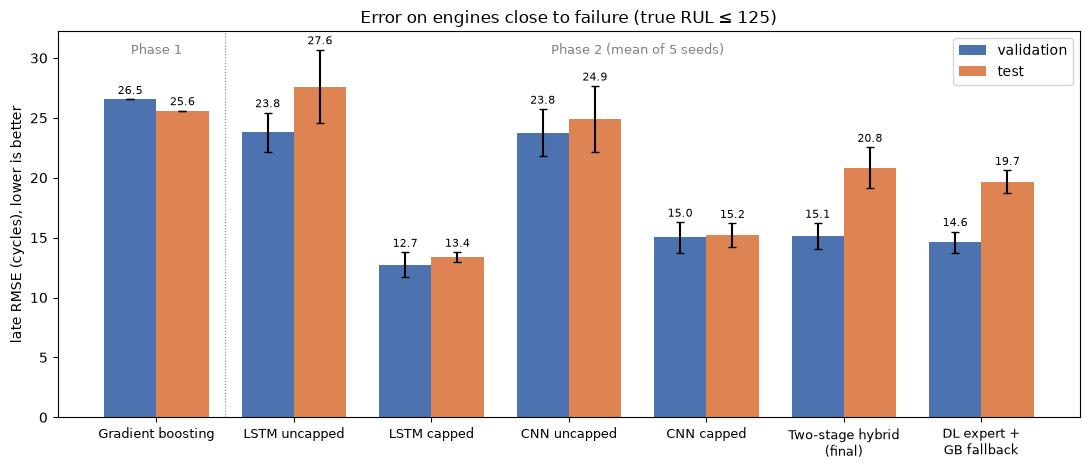

In [7]:
FIG_MODELS = ["Gradient boosting", *MAIN_PHASE2]


def late_std(set_name, model):
    s = PER_SEED[(set_name, model)]["late_rmse"]
    return s.std(ddof=1) if len(s) > 1 else 0.0


x = np.arange(len(FIG_MODELS))
wd = 0.38
fig, ax = plt.subplots(figsize=(11, 4.8))
for k, (set_name, colour) in enumerate([("validation", "#4C72B0"), ("test", "#DD8452")]):
    vals = [final.loc[(final["set"] == set_name) & (final["model"] == m), "late_rmse"].item() for m in FIG_MODELS]
    errs = [late_std(set_name, m) for m in FIG_MODELS]
    bars = ax.bar(x + (k - 0.5) * wd, vals, wd, yerr=errs, capsize=3, color=colour, label=set_name)
    ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
ax.set_xticks(x)
ax.set_xticklabels([m.replace(" (final)", "\n(final)").replace(" + ", " +\n") for m in FIG_MODELS], fontsize=9)
ax.axvline(0.5, color="grey", lw=0.8, ls=":")
ax.text(0, ax.get_ylim()[1] * 0.97, "Phase 1", ha="center", va="top", fontsize=9, color="grey")
ax.text(3.5, ax.get_ylim()[1] * 0.97, "Phase 2 (mean of 5 seeds)", ha="center", va="top", fontsize=9, color="grey")
ax.set_ylabel("late RMSE (cycles), lower is better")
ax.set_title("Error on engines close to failure (true RUL ≤ 125)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(f"{RESULTS}/late_error_phase1_vs_phase2.png", dpi=150)
plt.show()

## 5. Figure 2: predicted vs true on test

Seed 0 for the two LSTM models; gradient boosting has one run. The diagonal is a perfect prediction; points above it predict too much life (the dangerous side). The dashed line is true RUL = 125.

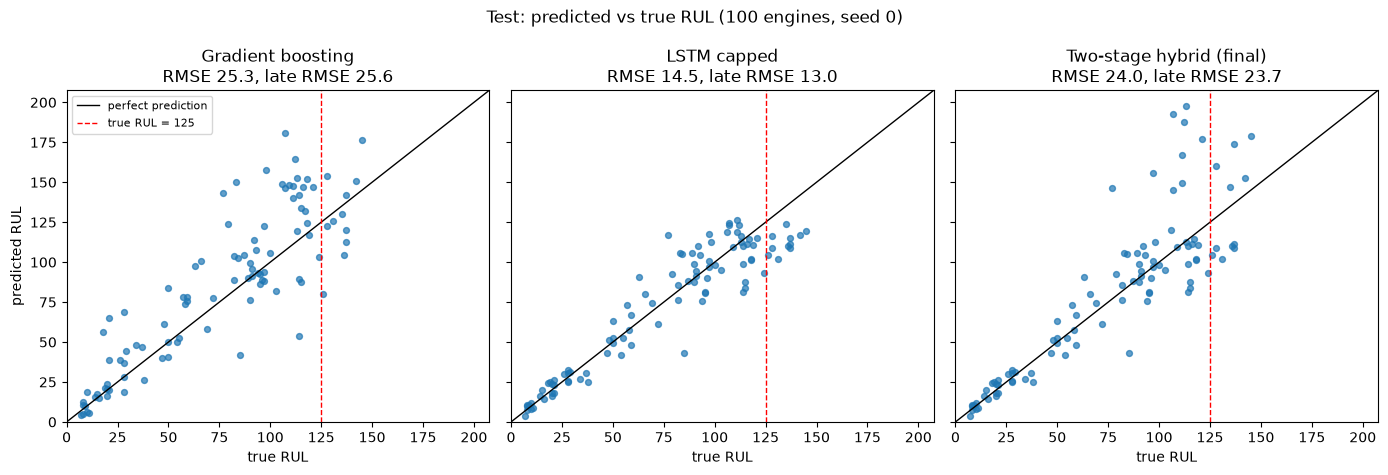

In [8]:
PANELS = ["Gradient boosting", "LSTM capped", "Two-stage hybrid (final)"]
lim = max(y_test.max(), max(PREDS[m][2][0].max() for m in PANELS)) * 1.05
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharex=True, sharey=True)
for ax, model in zip(axes, PANELS):
    p = PREDS[model][2][0]
    ax.scatter(y_test, p, s=18, alpha=0.7)
    ax.plot([0, lim], [0, lim], color="black", lw=1, label="perfect prediction")
    ax.axvline(LATE, color="red", ls="--", lw=1, label=f"true RUL = {LATE}")
    r = score_all(y_test, p)
    ax.set_title(f"{model}\nRMSE {r['rmse']:.1f}, late RMSE {r['late_rmse']:.1f}")
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("true RUL")
axes[0].set_ylabel("predicted RUL")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Test: predicted vs true RUL (100 engines, seed 0)")
fig.tight_layout()
fig.savefig(f"{RESULTS}/pred_vs_true_test.png", dpi=150)
plt.show()

## 6. Figure 3: why validation and test disagree

The two sets don't contain the same kind of engines. Validation has many far-from-failure points (true RUL up to ~330); the test engines are almost all close to failure.

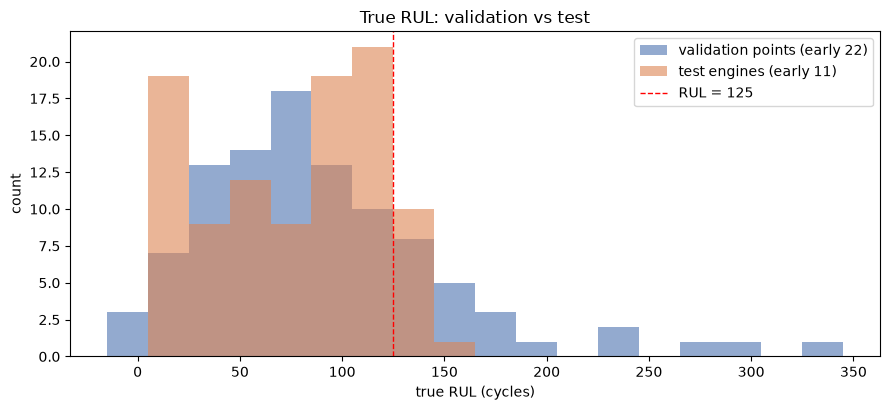

validation early 22  max true RUL 329  median 78
test       early 11  max true RUL 145  median 86


In [9]:
bins = np.arange(LATE - 140, max(y_val.max(), y_test.max()) + 20, 20)   # one edge exactly at 125
bins = bins[bins >= -15]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(y_val, bins=bins, alpha=0.6, label=f"validation points (early {int((y_val > LATE).sum())})", color="#4C72B0")
ax.hist(y_test, bins=bins, alpha=0.6, label=f"test engines (early {int((y_test > LATE).sum())})", color="#DD8452")
ax.axvline(LATE, color="red", ls="--", lw=1, label=f"RUL = {LATE}")
ax.set_xlabel("true RUL (cycles)")
ax.set_ylabel("count")
ax.set_title("True RUL: validation vs test")
ax.legend()
fig.tight_layout()
fig.savefig(f"{RESULTS}/val_vs_test_rul.png", dpi=150)
plt.show()

for name, y in [("validation", y_val), ("test", y_test)]:
    print(f"{name:10s} early {int((y > LATE).sum()):2d}  max true RUL {y.max():3d}  median {np.median(y):.0f}")

## 7. Missed late (hybrid)

A **missed late** point is a near-failure engine (true RUL ≤ 125) where the gate fired (capped prediction > 115), so it was handed to the uncapped model as if it were healthy. That is the dangerous mistake. Counted per seed, from the capped LSTM's own predictions.

In [10]:
cap_val, cap_test = PREDS["LSTM capped"][1], PREDS["LSTM capped"][2]
miss_rows = []
for set_name, y, cap in [("validation", y_val, cap_val), ("test", y_test, cap_test)]:
    late = y <= LATE
    for s in range(cap.shape[0]):
        missed = (cap[s] > GATE) & late
        miss_rows.append({"set": set_name, "seed": s, "sent_to_uncapped": int((cap[s] > GATE).sum()),
                          "missed_late": int(missed.sum()),
                          "missed_true_rul": " ".join(map(str, sorted(y[missed])))})
missed = pd.DataFrame(miss_rows)
display(missed)

for set_name, g in missed.groupby("set", sort=False):
    ruls = np.array([int(v) for s in g["missed_true_rul"] for v in s.split()])
    print(f"{set_name:10s} missed late per seed: {g['missed_late'].tolist()}  total {len(ruls)}, "
          f"true RUL {ruls.min()}–{ruls.max()}, above 100: {int((ruls > 100).sum())}")

,set,seed,sent_to_uncapped,missed_late,missed_true_rul
0,validation,0,17,5,108 109 109 117 121
1,validation,1,12,4,99 108 117 121
2,validation,2,17,6,89 99 108 109 109 117
3,validation,3,18,3,108 117 121
4,validation,4,22,5,99 108 109 117 121
5,test,0,15,10,77 97 106 107 107 111 111 112 113 121
6,test,1,11,8,98 107 107 111 112 113 119 121
7,test,2,13,9,97 98 106 107 107 111 111 112 113
8,test,3,20,14,77 97 98 106 107 107 109 111 111 112 113 116 1...
9,test,4,18,13,77 97 106 107 107 111 111 112 113 113 116 117 121


validation missed late per seed: [5, 4, 6, 3, 5]  total 23, true RUL 89–121, above 100: 19
test       missed late per seed: [10, 8, 9, 14, 13]  total 54, true RUL 77–121, above 100: 44


### Why the hybrid's NASA score is high

RMSE treats over- and under-prediction the same; the NASA score punishes over-prediction exponentially. Whenever the gate hands an engine to the uncapped LSTM and that model says "lots of life left" by too much, one engine can dominate the whole score. It happens both to near-failure engines the gate missed and to healthy engines the uncapped LSTM over-predicts (seed 4's worst engine has 137 cycles left).

In [11]:
hyb_test = PREDS["Two-stage hybrid (final)"][2]
gbf_test = PREDS["DL expert + GB fallback"][2]


def nasa_terms(y, p):
    d = p - y
    return np.where(d > 0, np.exp(d / 10) - 1, np.exp(-d / 13) - 1)


nasa_rows = []
for s in range(5):
    terms = nasa_terms(y_test, hyb_test[s])
    worst = int(np.argmax(terms))
    nasa_rows.append({
        "seed": s,
        "hybrid_nasa": terms.sum(),
        "share_from_over_prediction_pct": 100 * terms[hyb_test[s] > y_test].sum() / terms.sum(),
        "worst_engine": int(TEST_IDS[worst]), "worst_true_rul": int(y_test[worst]),
        "worst_predicted": round(float(hyb_test[s][worst]), 1), "worst_penalty": terms[worst],
        "gb_fallback_nasa": nasa_terms(y_test, gbf_test[s]).sum(),
    })
display(pd.DataFrame(nasa_rows).round(1))

,seed,hybrid_nasa,share_from_over_prediction_pct,worst_engine,worst_true_rul,worst_predicted,worst_penalty,gb_fallback_nasa
0,0,14360.9,99.1,78,107,192.9,5393.9,3042.0
1,1,2754.2,95.5,78,107,179.6,1425.3,2652.6
2,2,8412.2,98.1,23,113,201.8,7158.8,2722.3
3,3,10748.2,98.5,67,77,161.1,4480.6,3534.3
4,4,45410.0,99.8,83,137,241.2,33605.5,3199.2


## 8. Findings

All numbers come from `results/final_results_phase2.csv` and the cells above. Phase 2 numbers are means of 5 seeds (± = std of RMSE over seeds).

1. **Overall winner on validation: the two-stage hybrid.** RMSE 34.78 ± 2.27, MAE 20.32, R² 0.670, against 40.17 / 0.561 for the best Phase 1 model (gradient boosting). The GB-fallback version is a close second (35.22 ± 1.28) and steadier. This is the model we chose, on validation only.
2. **Error near failure is roughly halved compared with Phase 1.** Late RMSE on validation: gradient boosting 26.54 → capped LSTM 12.72, hybrid 15.15. On test: 25.61 → 13.36 and 20.84. Reading the raw sensor history helps exactly where it matters.
3. **Validation and test disagree on the single best model.** On test the capped LSTM wins (RMSE 14.76 ± 0.26, R² 0.874) and the hybrid (22.19 ± 1.74) falls behind every capped single model (14.76–17.99), the classifier version (18.19) and the GB-fallback version (20.14), though it still beats gradient boosting (25.33). The reason is the engines, not the models (Figure 3): validation has 22 early points with true RUL up to 329, test has 11 and its largest true RUL is 145. A capped model can't miss badly when nothing is far from failure, so this test set favours capping. We keep the hybrid: switching after seeing test would make the test score meaningless.
4. **Far-from-failure engines stay hard for every model.** Validation early RMSE is 62.16–84.99 for every model. A healthy engine's sensors are flat, so 200 and 300 cycles left look the same. Capped models are worst here (79.95–84.99) by design.
5. **What the extra metrics add.** R² ranks models the same as RMSE within a set but is easier to read (hybrid explains 67% of the variation on validation, gradient boosting 56%). Late recall alone can be gamed: the capped LSTM's validation recall of 1.00 comes from almost never predicting above 125, and its precision (0.79) shows the cost. The NASA score exposes the hybrid's weakness: 16,337 on test vs 4,813 for gradient boosting and 343 for the capped LSTM. 95.5–99.8% of it comes from over-predictions, and in seed 4 one engine (true RUL 137, predicted 241) adds 33,606 on its own. With GB as the fallback the score is 3,030 and steady across seeds.
6. **Memory ladder and other architectures.** The RNN (no gates) is the worst recurrent model on both sets (validation late RMSE 29.72 uncapped, 18.29 capped). The GRU ties the LSTM uncapped (35.76 ± 0.53 vs 36.28 ± 3.14, steadier) but the LSTM is the better near-failure expert (late 12.72 vs 13.55). The CNN-LSTM comes close to the capped LSTM (late 13.95) without beating it. On test the capped GRU (14.93) and CNN-LSTM (15.74) are next to the capped LSTM (14.76); test does not change the order chosen on validation.
7. **Other ways to combine models.** The separate classifier version is worse on validation (RMSE 40.33, late 18.17) than the gate. Averaging with gradient boosting moves validation RMSE by under 0.4 for the uncapped LSTM and the hybrid (36.28 → 35.98, 34.78 → 34.71), inside the seed noise; with the capped LSTM it lowers overall RMSE (39.79 → 38.29) but ruins late RMSE (12.72 → 17.93). Using GB as the fallback is the combination worth keeping (finding 1, and its NASA score of 3,030).
8. **Limits.** The gate misses 8–14 near-failure test engines per seed (54 in total over 5 seeds, true RUL 77–121, 44 of them above 100); on validation 3–6 per seed. Only 100 scored points per set, and test has just 11 early engines, so early-point numbers on test are thin. One C-MAPSS subset (FD001: one operating condition, one fault mode). Next steps: the other subsets (FD002–FD004) and more engines.